# Stage 5.3: Hypoxia Tendency Across All Basins

This notebook extends the hypoxia tendency analysis to include all major basins simultaneously.

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import seaborn as sns
import sys
import os
import yaml
from pathlib import Path
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set the global figure font size and style
plt.style.use('../project_style.mplstyle')

# Add project root to sys.path
cwd = Path(os.getcwd())
if (cwd / 'params.yaml').exists():
    project_root = cwd
else:
    project_root = cwd.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths

print("Project root:", project_root)


Project root: /home/reyha/SIS_Analysis_WSL


In [2]:
# Load parameters
with open(project_root / 'params.yaml', 'r') as f:
    params = yaml.safe_load(f)

REP_MONTH_SUMMER = params['seasonal_subsets']['representative_months']['Summer']

# Load the complete processed dataset
print(f"Loading data from: {ProjectPaths.MERGED_DATA_FILE}")
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# Filter for Summer Bottom DO for all regions
summer_bottom = merged_gdf[
    (merged_gdf['surveymont'] == REP_MONTH_SUMMER) &
    (merged_gdf['saisuipoin'] == 2)
].copy()

# Ensure DO is numeric and drop NaNs
summer_bottom['do_'] = pd.to_numeric(summer_bottom['do_'], errors='coerce')
summer_bottom = summer_bottom.dropna(subset=['do_'])

print(f"Total observations: {len(summer_bottom)}")
print(f"Unique stations: {summer_bottom['zettaicode'].nunique()}")
print(f"Regions included: {summer_bottom['watermass_name'].unique()}")


Loading data from: /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather


Total observations: 6523
Unique stations: 188
Regions included: ['Ise Bay' 'Tokyo Bay' 'Seto Inland Sea' None]


## 1. Temporal-Spatial Matrix and Heatmap
First, we construct a matrix of stations (rows) by years (columns) for the summer bottom DO. This helps us visualize the missing data patterns and overall DO status across different regions. Stations are sorted by region and mean DO to show coherent patterns.

In [3]:
# 1. Create Temporal-Spatial Matrix
pivot_df = summer_bottom.pivot_table(
    index='zettaicode',
    columns='year',
    values='do_',
    aggfunc='mean'
)

# Clean index
pivot_df.index = pivot_df.index.astype(str).str.zfill(8)

# Map stations to their region for sorting
station_regions = summer_bottom[['zettaicode', 'watermass_name']].drop_duplicates('zettaicode').set_index('zettaicode')['watermass_name']
pivot_df = pivot_df.join(station_regions)

# Sort by region, then by mean DO (descending)
pivot_df['mean_do'] = pivot_df.drop('watermass_name', axis=1).mean(axis=1)
pivot_df = pivot_df.sort_values(by=['watermass_name', 'mean_do'], ascending=[True, False])

mean_do_col = pivot_df['mean_do']
regions_col = pivot_df['watermass_name']
pivot_df = pivot_df.drop(['mean_do', 'watermass_name'], axis=1)

pivot_df.head()


,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00002337,6.7,6.3,8.8,6.1,6.5,8.7,5.3,6.0,6.4,7.4,...,7.2,NaN,6.2,6.4,8.4,6.4,6.2,6.5,5.7,6.8
00002434,5.1,NaN,5.5,8.4,8.6,4.0,5.3,6.1,5.7,7.5,...,7.4,7.4,6.5,6.1,6.8,6.2,6.3,4.2,9.9,7.0
00002343,6.9,4.9,6.4,6.4,6.7,7.4,6.4,5.8,5.1,7.8,...,6.8,NaN,6.3,6.2,6.6,5.3,6.7,6.7,6.6,6.9
00002355,5.2,3.4,6.6,9.0,10.7,6.6,7.3,2.3,6.9,5.4,...,9.5,NaN,3.0,2.9,10.8,1.8,2.5,9.8,2.7,7.2
00002423,9.6,NaN,8.1,5.3,4.4,5.1,5.8,5.4,7.0,7.0,...,5.2,4.0,6.0,5.4,6.2,5.8,6.1,3.5,6.7,2.6


Comparison plot saved to: /home/reyha/SIS_Analysis_WSL/figures/hypoxia_status_comparison_all_basins.png


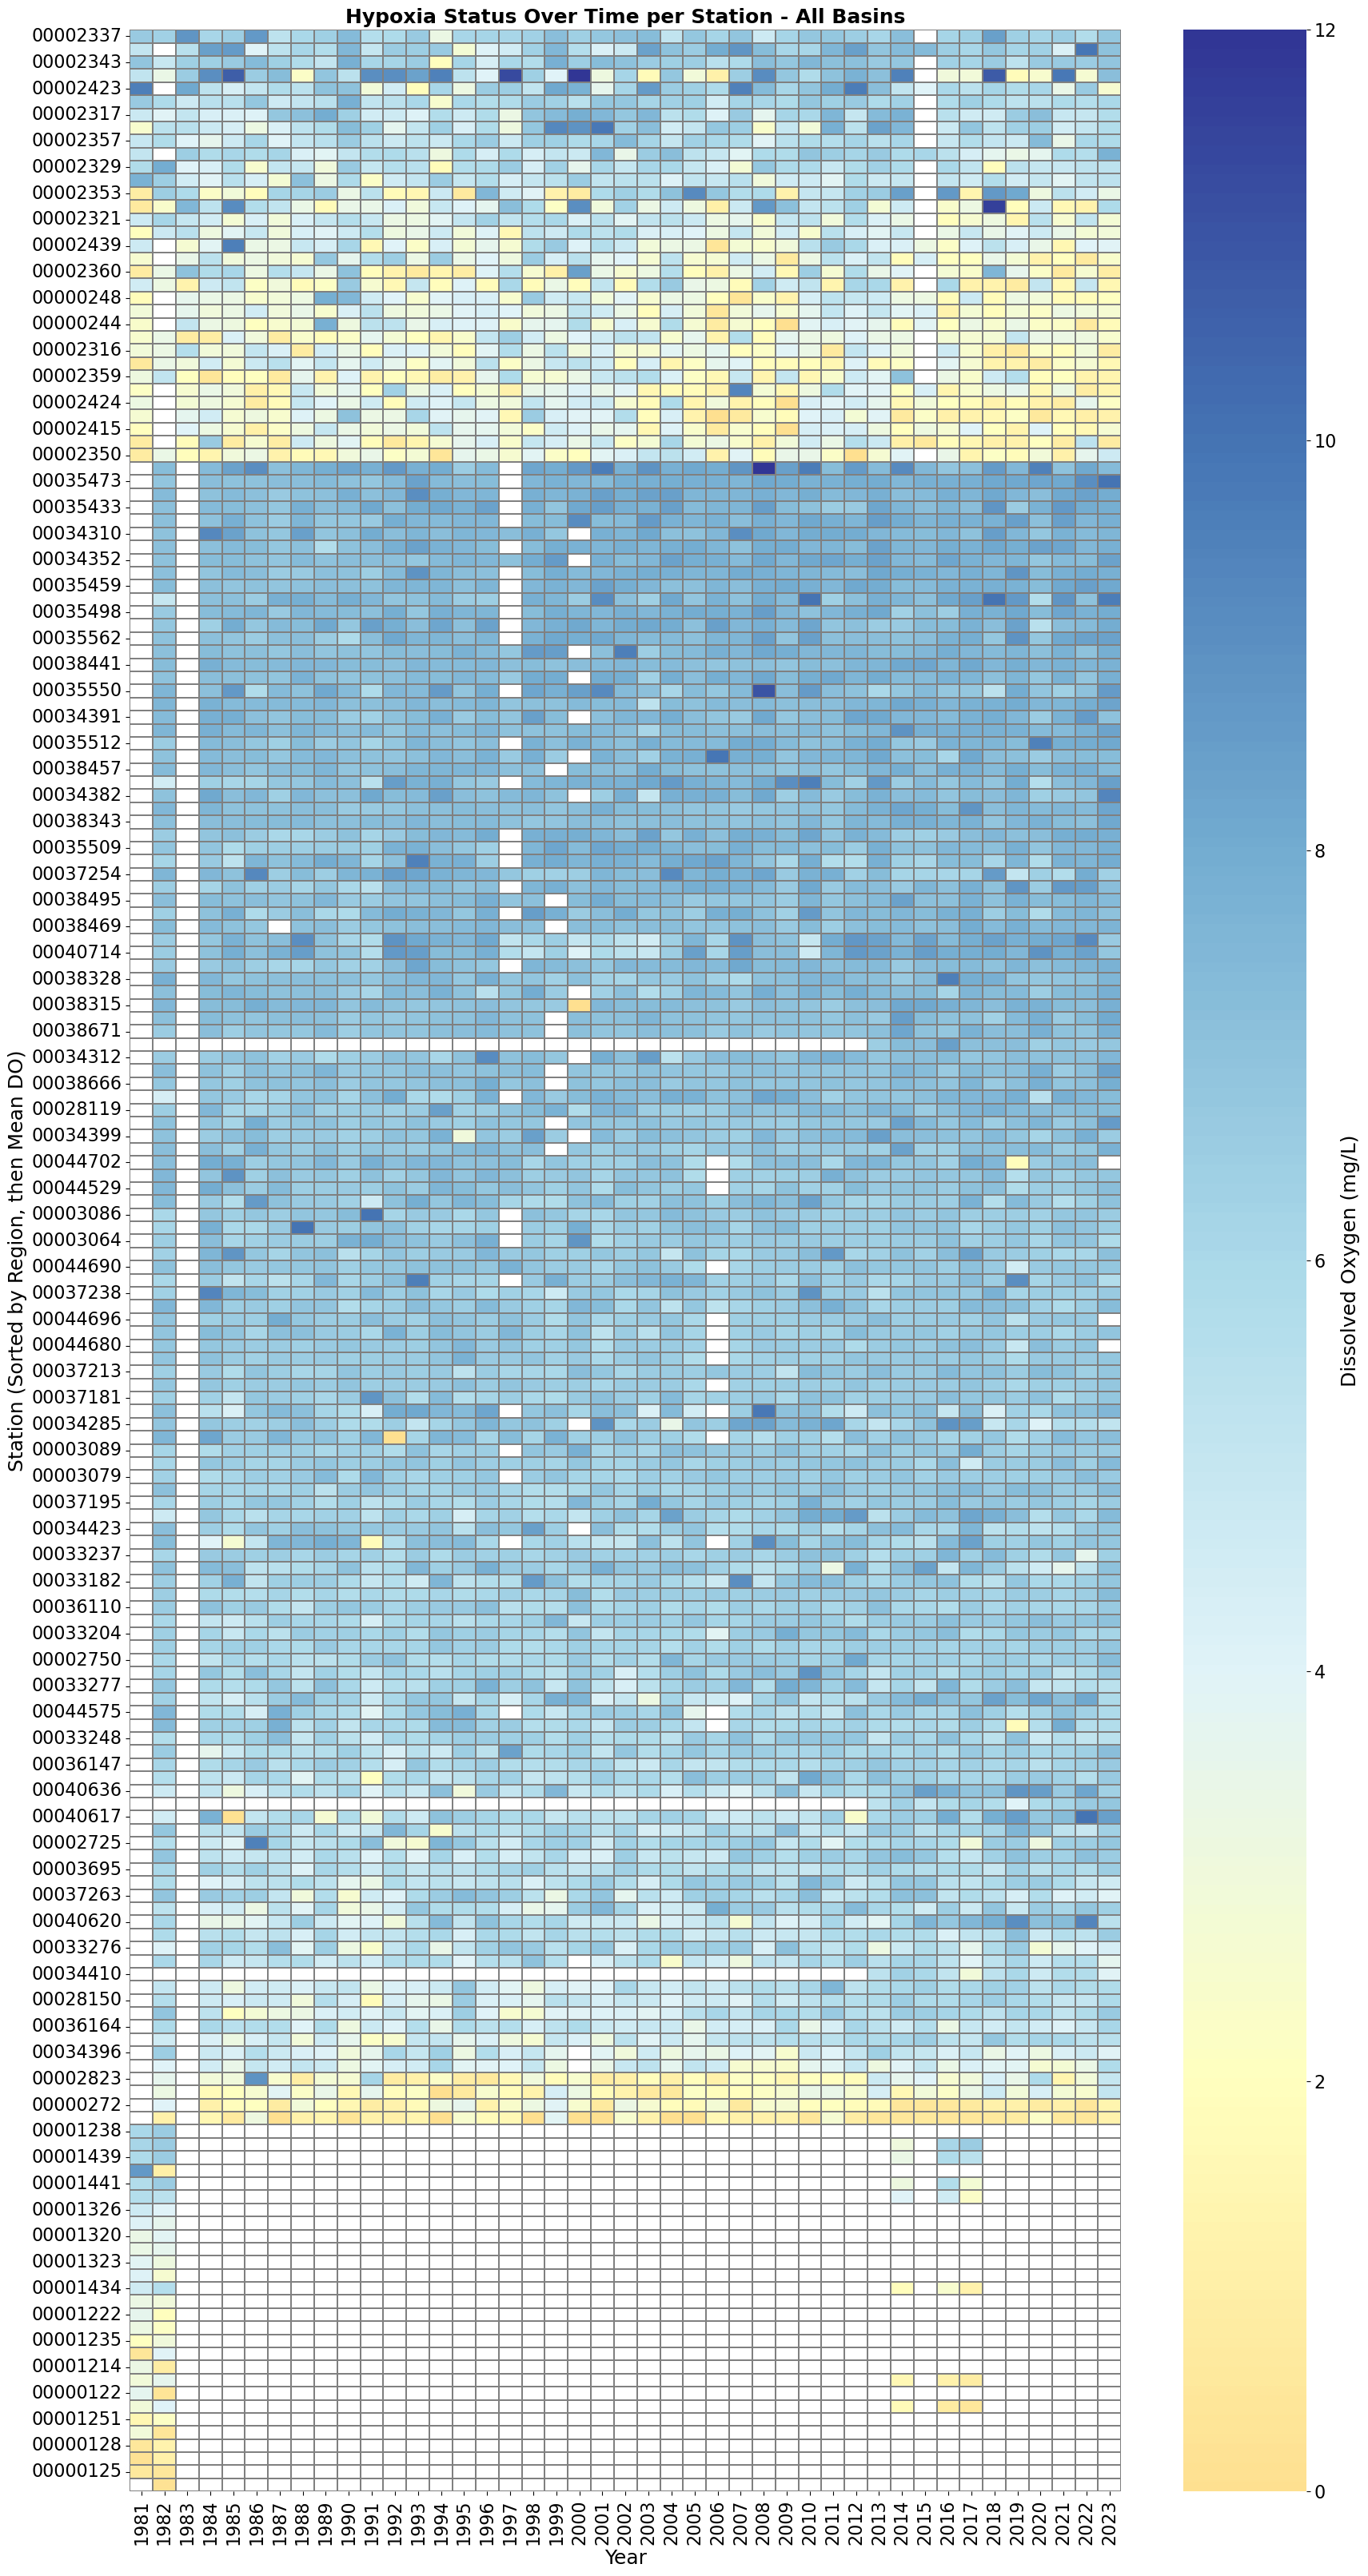

In [4]:
# 2. Visualization 1 (Heatmap)
plt.figure(figsize=(20, 40))
sns.heatmap(
    pivot_df, 
    cmap='RdYlBu', 
    center=2.0, # Center around hypoxic threshold (2 mg/L)
    cbar_kws={'label': 'Dissolved Oxygen (mg/L)'},
    linewidths=0.01,
    linecolor='gray'
)

plt.title('Hypoxia Status Over Time per Station - All Basins')
plt.ylabel('Station (Sorted by Region, then Mean DO)')
plt.xlabel('Year')

output_path = project_root / 'figures' / 'hypoxia_status_comparison_all_basins.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Comparison plot saved to: {output_path}")

plt.show()


## 2. Linear Trend Analysis
We calculate the linear regression slope (mg/L per year) for each station's summer bottom DO over the available time series. A positive slope indicates an improvement (increase in DO), while a negative slope indicates worsening hypoxia. We visualize the distribution of these slopes using a violin plot.

In [5]:
# 3. Trend Analysis
def calculate_slope(row):
    valid_mask = ~row.isna()
    if valid_mask.sum() < 5:  # Require at least 5 years of data
        return np.nan
    years = row.index[valid_mask].astype(float)
    values = row[valid_mask].values
    slope, intercept, r_value, p_value, std_err = stats.linregress(years, values)
    return slope

slopes = pivot_df.apply(calculate_slope, axis=1).dropna()
slopes_df = slopes.to_frame(name='do_slope_per_year')
slopes_df = slopes_df.join(regions_col).join(mean_do_col)
slopes_df.index.name = 'zettaicode'

worsening = slopes_df[slopes_df['do_slope_per_year'] < 0]
improving = slopes_df[slopes_df['do_slope_per_year'] > 0]

print(f"Stations with worsening trend: {len(worsening)}")
print(f"Stations with improving trend: {len(improving)}")


Stations with worsening trend: 69
Stations with improving trend: 98


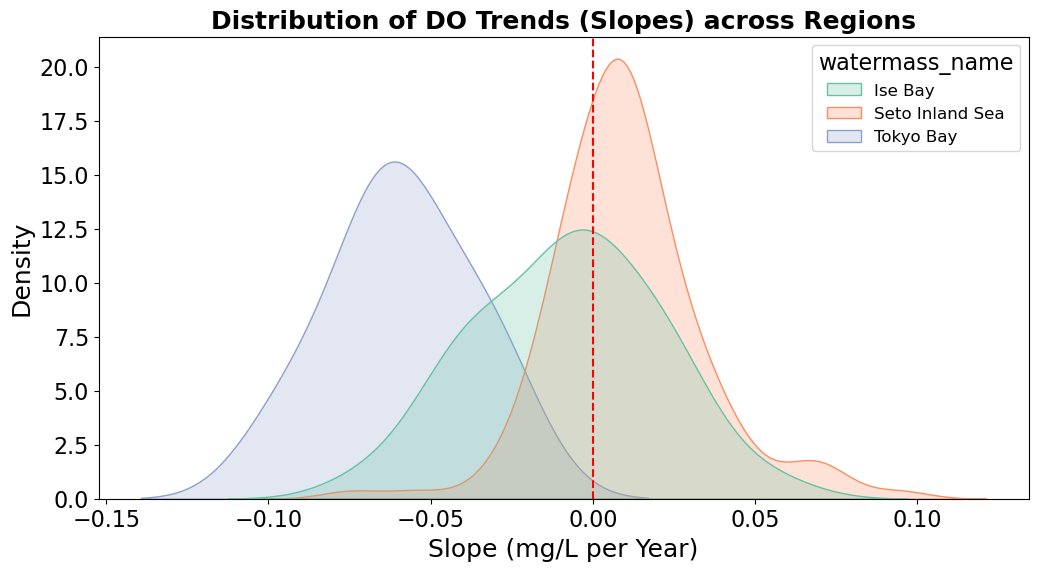

In [6]:
# 4. Visualization 2 (Trend Distribution)
plt.figure(figsize=(12, 6))
sns.kdeplot(data=slopes_df, x='do_slope_per_year', hue='watermass_name', fill=True, common_norm=False, palette='Set2')
plt.axvline(0, color='red', linestyle='--')
plt.title('Distribution of DO Trends (Slopes) across Regions')
plt.xlabel('Slope (mg/L per Year)')
plt.ylabel('Density')
plt.show()


## 3. Hypoxia Frequency Spatial Mapping
We map the frequency of hypoxia (defined as DO < 3.0 mg/L) across all regions. The marker size and color represent the percentage of years a station experienced hypoxic conditions.

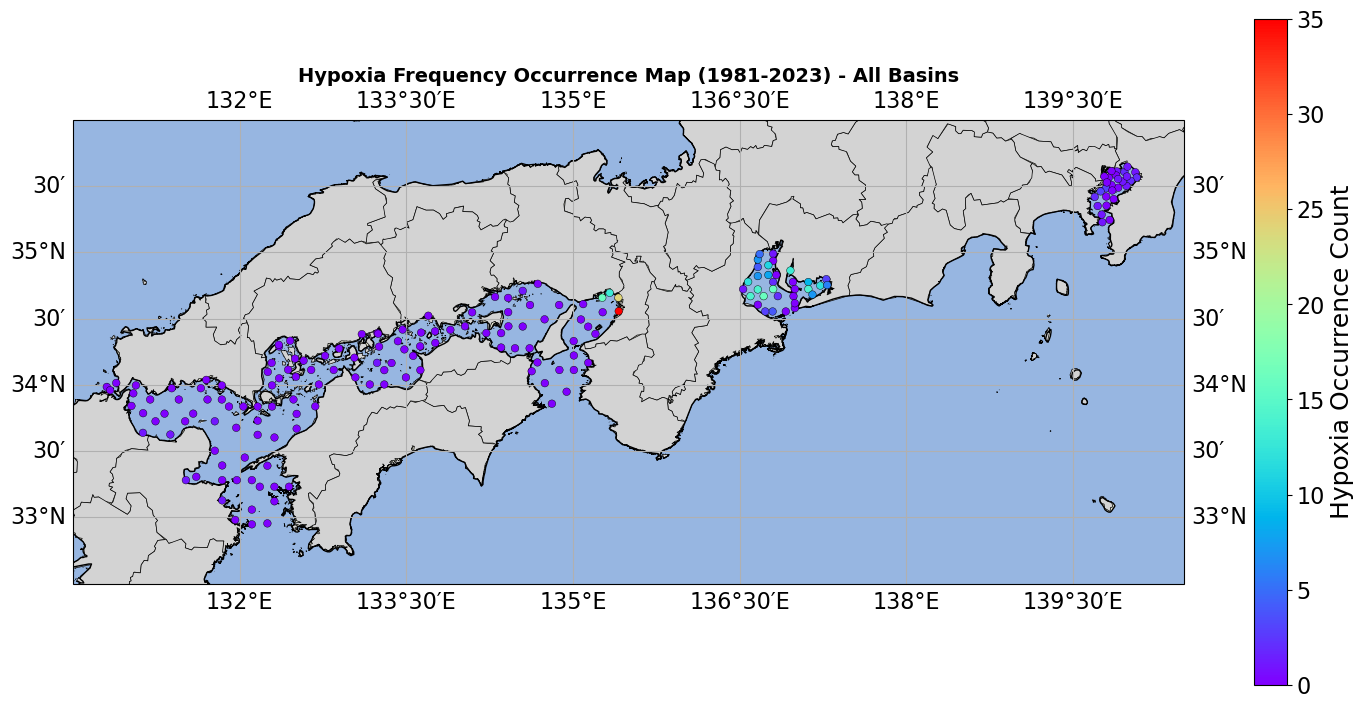

In [7]:
# 5. Visualization 3 (Hypoxia Frequency Map)
hypoxia_threshold = 2
hypoxia_df = summer_bottom[summer_bottom['do_'] < hypoxia_threshold]       
station_counts = hypoxia_df.groupby('zettaicode')['year'].nunique().reset_index(name='hypoxia_count')       
all_stations = summer_bottom[['zettaicode', 'geometry']].drop_duplicates('zettaicode')                   
plot_data = all_stations.merge(station_counts, on='zettaicode', how='left')      
plot_data['hypoxia_count'] = plot_data['hypoxia_count'].fillna(0) 

# Load boundary
boundary_path = ProjectPaths.BOUNDARIES_DIR / "Whole nation administrative boundary" / "N03-20240101_prefecture(simplified0.01).shp"
if boundary_path.exists():
    japan_boundary = gpd.read_file(boundary_path)
    if japan_boundary.crs != "EPSG:4326":
        japan_boundary = japan_boundary.to_crs("EPSG:4326")
else:
    print(f"Warning: Boundary file not found at {boundary_path}")
    japan_boundary = None

fig = plt.figure(figsize=(15, 10))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

# Bounding box for Seto Inland Sea, Tokyo Bay, Ise Bay
ax.set_extent([130.5, 140.5, 32.5, 36.0], crs=ccrs.PlateCarree())

if japan_boundary is not None:
    japan_boundary.plot(ax=ax, facecolor='lightgray', edgecolor='black', linewidth=0.5, transform=ccrs.PlateCarree(), zorder=1)

ax.coastlines()
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

sc = ax.scatter(
    plot_data.geometry.x, 
    plot_data.geometry.y, 
    s=30,
    alpha=1,
    c=plot_data['hypoxia_count'],
    cmap='rainbow',
    vmin=0, 
    vmax=None,
    transform=ccrs.PlateCarree(),
    edgecolors='black',
    linewidth=0.3,
    zorder=2
)

cbar = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.05)
cbar.set_label('Hypoxia Occurrence Count')
ax.set_title('Hypoxia Frequency Occurrence Map (1981-2023) - All Basins', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Principal Component Analysis (PCA)
To identify the dominant modes of variability in the DO time series, we perform PCA. We first impute missing years using the station mean, then extract the principal components. We plot the spatial loadings (eigenvectors) to see which regions co-vary, and the PCA scores to understand the temporal progression of these modes.

In [8]:
# 6. Concise PCA Analysis
pca_data = pivot_df.dropna(thresh=1, axis=0) # Keep stations with at least 50% valid years
# Impute missing values with row mean (station mean)
pca_data = pca_data.apply(lambda row: row.fillna(row.mean()), axis=1)

# Transpose so rows = years, cols = stations
pca_data_T = pca_data.T

scaler = StandardScaler()
pca_data_scaled = scaler.fit_transform(pca_data_T)

pca = PCA(n_components=5)
pca_scores = pca.fit_transform(pca_data_scaled)

# Create a DataFrame for eigenvectors
eigenvectors = pd.DataFrame(pca.components_.T, index=pca_data.index, columns=[f"PC{i+1}" for i in range(5)])
eigenvectors = eigenvectors.join(regions_col, how='inner')

# Create a DataFrame for PCA scores
scores_df = pd.DataFrame(pca_scores, index=pca_data_T.index, columns=[f"PC{i+1}" for i in range(5)])

print(f"Explained variance ratio: {pca.explained_variance_ratio_}")


Explained variance ratio: [0.12610201 0.0993772  0.06670563 0.04670176 0.0438481 ]


Merge Result: 188 stations matched out of 188 PCA stations.


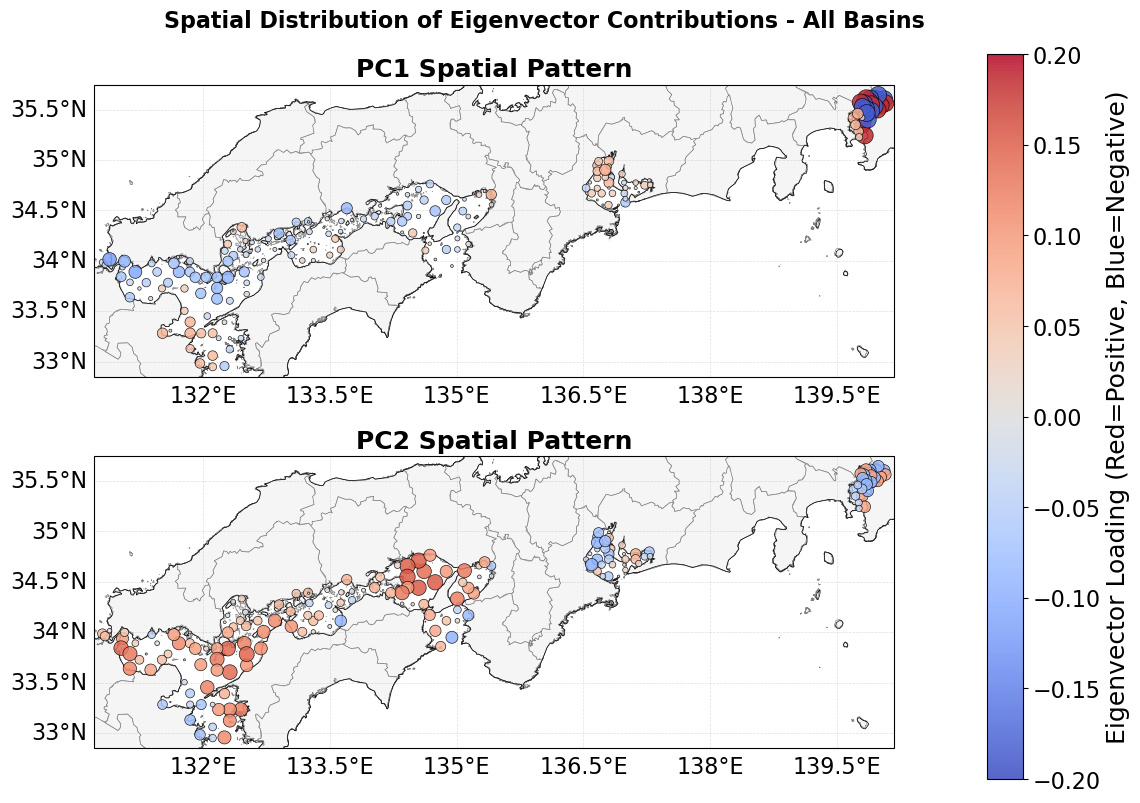

In [9]:
# 7. Visualization 4 (PCA Eigenvector Contribution Map)
# 1. Get Eigenvectors (Loadings)
pc1_loadings = pca.components_[0]
pc2_loadings = pca.components_[1]

# 2. Get Station Coordinates
gdf_unique_stations = summer_bottom[['zettaicode', 'geometry']].drop_duplicates(subset='zettaicode').copy()

# 3. Create loadings DataFrame
station_ids = pca_data.index.tolist()

loadings_df = pd.DataFrame({
    'zettaicode': station_ids,
    'PC1_Loading': pc1_loadings,
    'PC2_Loading': pc2_loadings
})

loadings_df['zettaicode'] = loadings_df['zettaicode'].astype(str)
gdf_unique_stations['zettaicode'] = gdf_unique_stations['zettaicode'].astype(str)
loadings_map_data = gdf_unique_stations.merge(loadings_df, on='zettaicode', how='inner')

print(f"Merge Result: {len(loadings_map_data)} stations matched out of {len(station_ids)} PCA stations.")

# 4. Dynamically calculate figure height to match Cartopy's enforced aspect ratio
n_rows, n_cols = 2, 1
pad = 0.1
min_lon, min_lat, max_lon, max_lat = loadings_map_data.total_bounds
extent = [min_lon - pad, max_lon + pad, min_lat - pad, max_lat + pad]

aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])
fig_width = 12
width_per_subplot = fig_width / n_cols
height_per_subplot = (width_per_subplot * aspect_ratio) + 0.3
fig_height = (height_per_subplot * n_rows) + 1.0

# 5. Plotting (Vertical Stack)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height),
                         subplot_kw={'projection': ccrs.PlateCarree()})

fig.suptitle('Spatial Distribution of Eigenvector Contributions - All Basins', fontsize=16, fontweight='bold')

components = [('PC1_Loading', 'PC1'), ('PC2_Loading', 'PC2')]

for ax, (col, title) in zip(axes, components):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    
    if japan_boundary is not None:
        japan_boundary.plot(ax=ax, facecolor='whitesmoke', edgecolor='gray', linewidth=0.5, transform=ccrs.PlateCarree(), zorder=1)
    else:
        ax.add_feature(cfeature.LAND, facecolor='whitesmoke', edgecolor='gray')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4, linewidth=0.5)
    gl.top_labels = False
    gl.right_labels = False

    sc = ax.scatter(
        loadings_map_data.geometry.x,
        loadings_map_data.geometry.y,
        c=loadings_map_data[col],
        s=loadings_map_data[col].abs() * 800,
        cmap='coolwarm',
        edgecolor='k',
        linewidth=0.5,
        alpha=0.85,
        transform=ccrs.PlateCarree(),
        vmin=-0.2, vmax=0.2,
        zorder=2
    )
    ax.set_title(f'{title} Spatial Pattern', fontweight='bold')

plt.subplots_adjust(hspace=0.05, top=0.93, bottom=0.12)
cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), orientation='vertical', fraction=0.04, pad=0.1)
cbar.set_label('Eigenvector Loading (Red=Positive, Blue=Negative)')

plt.show()

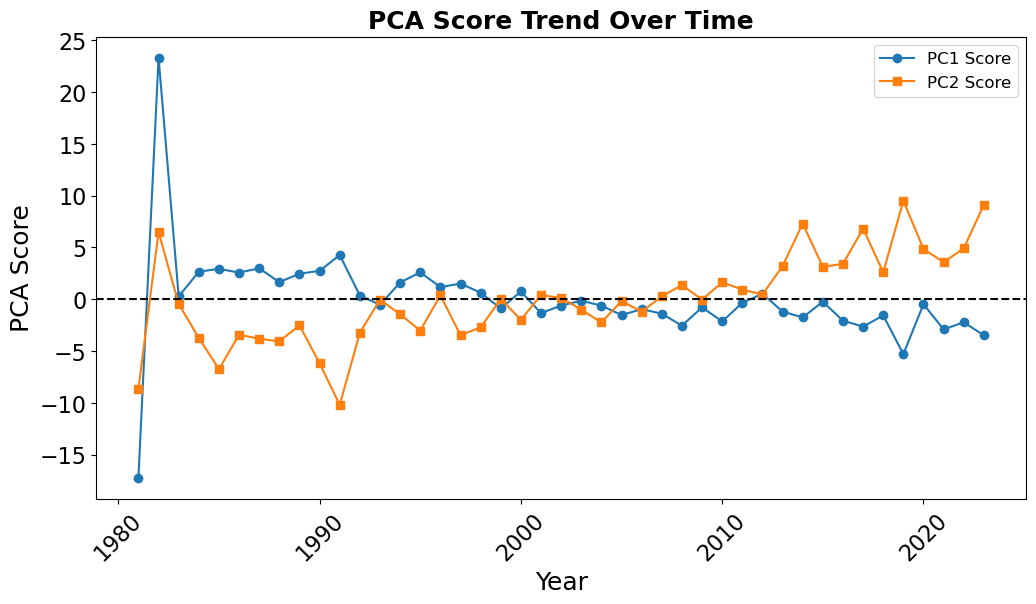

In [10]:
# 8. Visualization 5 (PCA Score Trend)
plt.figure(figsize=(12, 6))
plt.plot(scores_df.index, scores_df['PC1'], marker='o', label='PC1 Score')
plt.plot(scores_df.index, scores_df['PC2'], marker='s', label='PC2 Score')
plt.axhline(0, color='black', linestyle='--')
plt.title('PCA Score Trend Over Time')
plt.xlabel('Year')
plt.ylabel('PCA Score')
plt.xticks(rotation=45)
plt.legend()
plt.show()


## 5. Data Export
Finally, we merge the calculated DO slopes and PCA eigenvectors into a single dataset and export it to a CSV file for further downstream analysis.

In [ ]:
# 9. Data Export
# Merge slopes and eigenvectors
final_export_df = slopes_df.join(eigenvectors[[f"PC{i+1}" for i in range(5)]], how='outer')

output_csv = project_root / 'data' / 'processed' / 'hypoxia_tendency_slopes_all.csv'
final_export_df.to_csv(output_csv)
print(f"Results saved to: {output_csv}")

Results saved to: /home/reyha/SIS_Analysis_WSL/data/processed/hypoxia_tendency_slopes_all.csv
